In [1]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import joblib
import anndata as ad
from scipy.signal import find_peaks
import h5py



In [2]:
prot = joblib.load("C:\\Users\\olesk\\data\\all_prot_points_0818.sav")
umap_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_points_0818.sav")
prot_d = joblib.load("C:\\Users\\olesk\\data\\all_prot_points_cycdi_0818.sav")
umap_d_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_points_cycdi_0818.sav")

In [3]:
adata = ad.read_h5ad('C:\\Users\\olesk\\repos\\ECM_cell_cycle_model\\Python\\orig_params_0818_w_cycdi-wELong.h5ad')

In [4]:
adata.obs.columns

Index(['drug', 'stiffness', 'inhibitor', 'G1_time'], dtype='object')

In [5]:
def getIMT(prot):
    peaks_E, _ = find_peaks(prot[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    time_st = 0.1

    #Padding for beginning of run
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    tmp_ind = tmp
    div_time = pd.DataFrame(tmp)

    div_inds = pd.DataFrame(tmp)
    div_phase = pd.DataFrame(tmp)
    ii=0
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp_ind = [np.array([ii])]*int(ordered[2]-ordered[0])
            tmp_g1 = ['G1']*int(ordered[2]-ordered[1])
            tmp_s_m = ['S-G2-M']*int(ordered[1]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_ind = np.concatenate(tmp_ind, axis=0)

            tmp_df = pd.DataFrame(tmp)
            tmp_df_ind = pd.DataFrame(tmp_ind)
            tmp_g1_df = pd.DataFrame(tmp_g1)
            tmp_s_m_df = pd.DataFrame(tmp_s_m)            

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
            div_inds = pd.concat([div_inds, tmp_df_ind], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_s_m_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_g1_df], ignore_index=True)
            
            ii+=1
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
            div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
            div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)

            ii+=1

    # Padding for end of run
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
    div_phase = pd.concat([div_phase, tmp_df], ignore_index=True)
    
    return div_time, div_inds, div_phase

In [6]:
tmp_g1 = ['G1']*int(5)
tmp_g1_df = pd.DataFrame(tmp_g1)
tmp_g1_df

,0
0,G1
1,G1
2,G1
3,G1
4,G1


In [7]:
len_prot = int(prot.shape[0]/6)
win_len = int(prot.shape[1]/18)

In [8]:
all_divs = []
all_div_inds = []
all_phase = []
for num in range(6):
    tmp_div, div_inds, div_phase = getIMT(prot[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    tmp_phase = div_phase[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    all_phase = all_phase + tmp_phase
    print(num)

0
1
2
3
4
5


In [9]:
for num in range(6):
    tmp_div, div_inds, div_phase = getIMT(prot_d[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    tmp_phase = div_phase[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    all_phase = all_phase + tmp_phase
    print(num)

0
1
2
3
4
5


In [10]:
prot_names = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]

In [11]:
alldata = adata.obs
alldata['G1_val'] = all_divs
alldata['Phase'] = all_phase
alldata['cell_ind'] = all_div_inds
alldata['UMAP1'] = adata.obsm["X_umap"][:,0]
alldata['UMAP2'] = adata.obsm["X_umap"][:,1]
# alldata['G1_time'] = adata.obs["G1_time"]
n=1
for name in prot_names:
    alldata[f"{name}"] = adata.X[:,n]
    n+=3

nan

In [12]:
test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0.2) & (alldata['inhibitor'] == 'none')]


In [13]:
tmp = test.loc[(test['G1_time'] == 'Long')]

In [14]:
test

,drug,stiffness,inhibitor,G1_time,G1_val,Phase,cell_ind,UMAP1,UMAP2,skp2,...,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
win_39993,ERL,0.2,none,nan,NaN,NaN,NaN,-1.096727,3.414600,0.196078,...,0.659509,0.395349,0.216080,0.645,0.057471,0.710383,0.022222,0.144330,0.018182,0.060302
win_39994,ERL,0.2,none,nan,NaN,NaN,NaN,-1.532531,3.680125,0.215686,...,0.677914,0.409302,0.175879,0.520,0.045977,0.754098,0.011111,0.164948,0.018182,0.070352
win_39995,ERL,0.2,none,nan,NaN,NaN,NaN,-2.219610,4.204575,0.215686,...,0.634969,0.320930,0.256281,0.390,0.057471,0.797814,0.011111,0.216495,0.018182,0.065327
win_39996,ERL,0.2,none,nan,NaN,NaN,NaN,-2.828619,4.713120,0.235294,...,0.598159,0.269767,0.306533,0.265,0.045977,0.781421,0.055556,0.273196,0.018182,0.055276
win_39997,ERL,0.2,none,nan,NaN,NaN,NaN,-3.372991,5.205406,0.215686,...,0.558282,0.181395,0.361809,0.160,0.034483,0.814208,0.044444,0.340206,0.018182,0.080402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
win_79981,ERL,0.2,none,nan,NaN,NaN,NaN,14.070481,5.723105,0.039216,...,0.012270,0.004651,0.422111,0.000,0.057471,0.000000,0.344444,0.041237,0.600000,0.040201
win_79982,ERL,0.2,none,nan,NaN,NaN,NaN,14.069191,5.698688,0.039216,...,0.006135,0.000000,0.432161,0.000,0.068966,0.010929,0.322222,0.051546,0.563636,0.035176
win_79983,ERL,0.2,none,nan,NaN,NaN,NaN,14.076811,5.691776,0.039216,...,0.018405,0.000000,0.427136,0.005,0.057471,0.005464,0.333333,0.061856,0.527273,0.005025
win_79984,ERL,0.2,none,nan,NaN,NaN,NaN,14.079397,5.596808,0.039216,...,0.052147,0.018605,0.402010,0.005,0.057471,0.000000,0.366667,0.061856,0.527273,0.020101


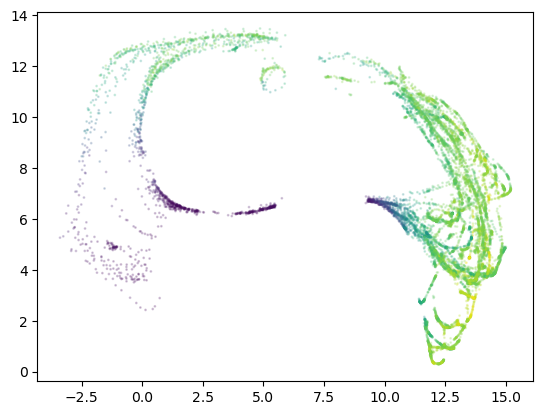

In [15]:
plt.scatter(tmp.UMAP1, tmp.UMAP2, c=tmp.Rb, s=1, alpha=0.2)

In [16]:
test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0.2) & (alldata['inhibitor'] == 'none')]


In [17]:
test

,drug,stiffness,inhibitor,G1_time,G1_val,Phase,cell_ind,UMAP1,UMAP2,skp2,...,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
win_39993,ERL,0.2,none,nan,NaN,NaN,NaN,-1.096727,3.414600,0.196078,...,0.659509,0.395349,0.216080,0.645,0.057471,0.710383,0.022222,0.144330,0.018182,0.060302
win_39994,ERL,0.2,none,nan,NaN,NaN,NaN,-1.532531,3.680125,0.215686,...,0.677914,0.409302,0.175879,0.520,0.045977,0.754098,0.011111,0.164948,0.018182,0.070352
win_39995,ERL,0.2,none,nan,NaN,NaN,NaN,-2.219610,4.204575,0.215686,...,0.634969,0.320930,0.256281,0.390,0.057471,0.797814,0.011111,0.216495,0.018182,0.065327
win_39996,ERL,0.2,none,nan,NaN,NaN,NaN,-2.828619,4.713120,0.235294,...,0.598159,0.269767,0.306533,0.265,0.045977,0.781421,0.055556,0.273196,0.018182,0.055276
win_39997,ERL,0.2,none,nan,NaN,NaN,NaN,-3.372991,5.205406,0.215686,...,0.558282,0.181395,0.361809,0.160,0.034483,0.814208,0.044444,0.340206,0.018182,0.080402
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
win_79981,ERL,0.2,none,nan,NaN,NaN,NaN,14.070481,5.723105,0.039216,...,0.012270,0.004651,0.422111,0.000,0.057471,0.000000,0.344444,0.041237,0.600000,0.040201
win_79982,ERL,0.2,none,nan,NaN,NaN,NaN,14.069191,5.698688,0.039216,...,0.006135,0.000000,0.432161,0.000,0.068966,0.010929,0.322222,0.051546,0.563636,0.035176
win_79983,ERL,0.2,none,nan,NaN,NaN,NaN,14.076811,5.691776,0.039216,...,0.018405,0.000000,0.427136,0.005,0.057471,0.005464,0.333333,0.061856,0.527273,0.005025
win_79984,ERL,0.2,none,nan,NaN,NaN,NaN,14.079397,5.596808,0.039216,...,0.052147,0.018605,0.402010,0.005,0.057471,0.000000,0.366667,0.061856,0.527273,0.020101


In [18]:
tmp_ls = test.loc[(test['G1_time'] == 'Short') | (test['G1_time'] == 'Long')]

In [19]:
tmp_s = tmp_ls.loc[(tmp_ls['G1_time'] == 'Short')]
tmp_s_G1 = tmp_s.loc[(tmp_s['Phase'] == 'G1')]
tmp_s_SM = tmp_s.loc[(tmp_s['Phase'] == 'S-G2-M')]
tmp_l = tmp_ls.loc[(tmp_ls['G1_time'] == 'Long')]
tmp_l_G1 = tmp_l.loc[(tmp_l['Phase'] == 'G1')]
tmp_l_SM = tmp_l.loc[(tmp_l['Phase'] == 'S-G2-M')]

In [23]:
def plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool):
    xmin, xmax = -10, 20
    ymin, ymax = 0, 20
    
    if short_bool:        
        x = np.array(tmp_s.UMAP1)
        y = np.array(tmp_s.UMAP2)
        H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='gray', s=0.5, alpha=0.2)
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)

    else:
        x = np.array(tmp_l.UMAP1)
        y = np.array(tmp_l.UMAP2)
        H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='gray', s=0.5, alpha=0.2)
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)
        
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.xaxis.set_ticks(np.arange(-10, 21, step=10))
    ax.yaxis.set_ticks(np.arange(-2, 21, step=5))
    ax.tick_params(colors='white', which='both') 
    ax.set_title(prot, y=1.0, pad=-14, size=12)
    # plt.xticks(color='w')
    # plt.yticks(color='w')
    

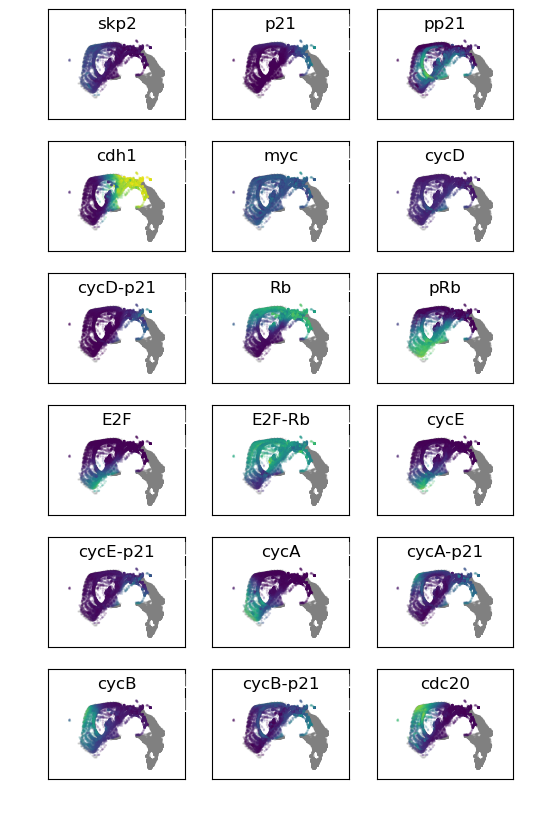

In [24]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=True)
    n+=1

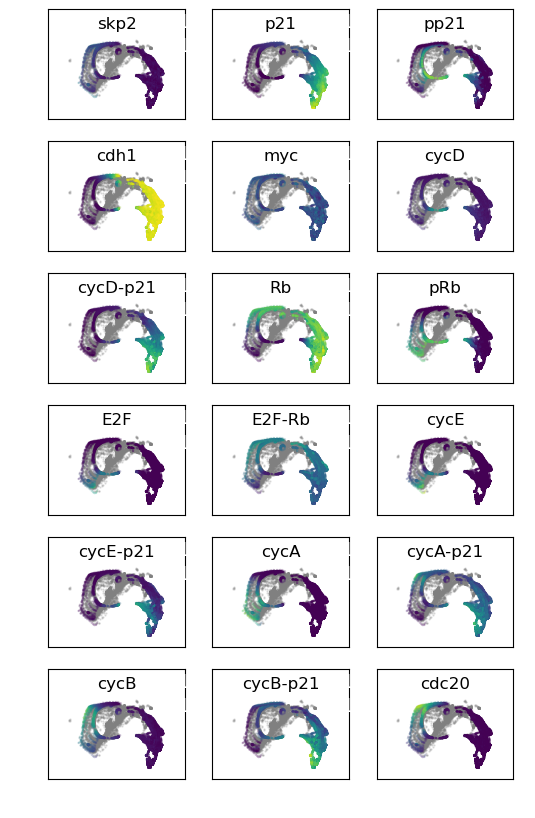

In [25]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=False)
    n+=1

(array([-2,  3,  8, 13, 18]),
 [Text(0, -2, '−2'),
  Text(0, 3, '3'),
  Text(0, 8, '8'),
  Text(0, 13, '13'),
  Text(0, 18, '18')])

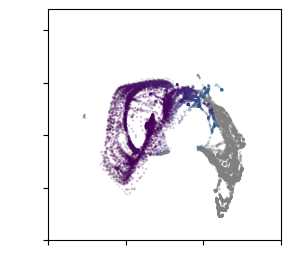

In [71]:
size = (3,3)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig, ax = plt.subplots(1,1, figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(tmp_s.UMAP1)
y = np.array(tmp_s.UMAP2)
H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='gray', s=0.5, alpha=0.2)
ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s['cycD-p21'], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(-2, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

(array([-2,  3,  8, 13, 18]),
 [Text(0, -2, '−2'),
  Text(0, 3, '3'),
  Text(0, 8, '8'),
  Text(0, 13, '13'),
  Text(0, 18, '18')])

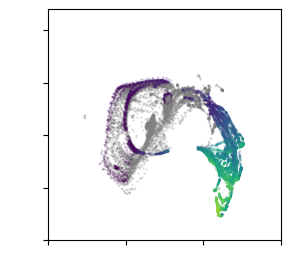

In [72]:
size = (3,3)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(tmp_l.UMAP1)
y = np.array(tmp_l.UMAP2)
H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='gray', s=0.5, alpha=0.2)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l['cycD-p21'], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(-2, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

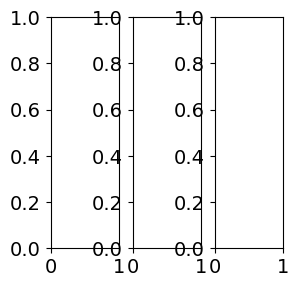

In [28]:
fig, axes = plt.subplots(1, 3, figsize=size)

In [29]:
import matplotlib.path as mpltPath

In [61]:
# H_s = np.swapaxes(H_s,0,1)
# H_l = np.swapaxes(H_l,0,1)

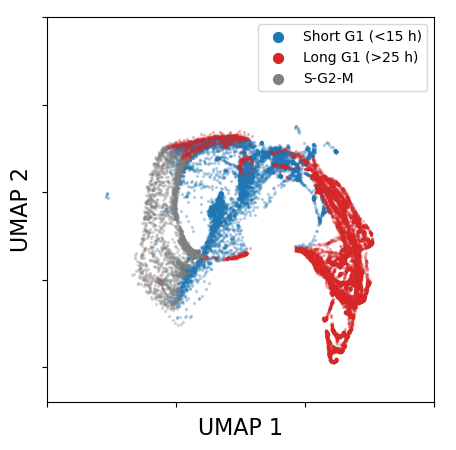

In [73]:
# max_level = 0.01
# min_level = 0.001
# step_level = 0.01
val = 0.0001
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = -2, 20

# c1 = plt.contour(y_centers, x_centers, H, levels = np.arange(min_level, max_level + step_level, step_level))
# c1 = plt.contour(y_centers, x_centers, H_s, [val], colors='tab:blue', alpha=0.5)
# c2 = plt.contour(y_centers, x_centers, H_l, [val], colors='tab:red', alpha=0.5)

plt.scatter(tmp_s_G1.UMAP1, tmp_s_G1.UMAP2, c='tab:blue', s=2, alpha=0.25, label='Short G1 (<15 h)')
plt.scatter(tmp_l_G1.UMAP1, tmp_l_G1.UMAP2, c='tab:red', s=2, alpha=0.25, label='Long G1 (>25 h)')
plt.scatter(tmp_l_SM.UMAP1, tmp_l_SM.UMAP2, c='gray', s=2, alpha=0.25, label='S-G2-M') 
plt.scatter(tmp_s_SM.UMAP1, tmp_s_SM.UMAP2, c='gray', s=2, alpha=0.25)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

plt.xlabel('UMAP 1', labelpad=-10)
plt.ylabel('UMAP 2', labelpad=-15)

leg = plt.legend(markerscale=5)
for lh in leg.legend_handles: 
    lh.set_alpha(1)

In [31]:
def OnePointInsideContour(contourArray, PointTuple, tol):
    L = len(contourArray);
    y0 = PointTuple[0]; # horizontal
    x0 = PointTuple[1]; # vertical
    ret = [];
    inside = False;
    counter = 0

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if ycont > y0 - tol and ycont < y0 + tol and xcont > x0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if ycont > y0 - tol and ycont < y0 + tol and xcont < x0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break           

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if xcont > x0 - tol and xcont < x0 + tol and ycont < y0:
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break  

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if xcont > x0 - tol and xcont < x0 + tol and ycont > y0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break

    if counter == 4:
        inside = True

    return inside, ret

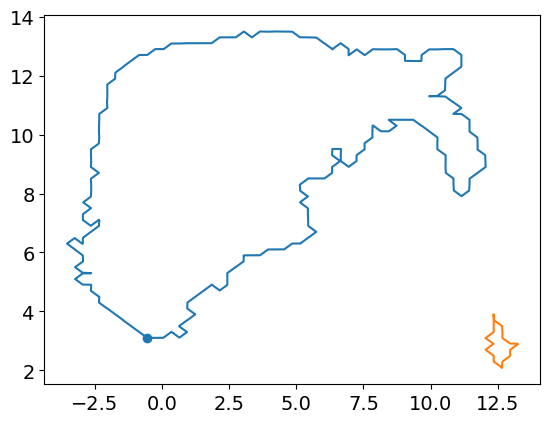

In [32]:
plt.plot(c1.allsegs[0][1][:,0], c1.allsegs[0][1][:,1])
plt.plot(c2.allsegs[0][3][:,0], c2.allsegs[0][3][:,1])
plt.scatter(c1.allsegs[0][1][0,0], c1.allsegs[0][1][0,1])

In [34]:
tmp_p = [(c1.allsegs[0][1][0,0], c1.allsegs[0][1][0,1])]
tmp_p

[(-0.5500000000000007, 3.1055668)]

In [35]:
cont = c1.allsegs[0][1]

In [36]:
tmp_p = [(5, 10)]

In [37]:
len(c2.allsegs[0])

37

In [38]:
path = mpltPath.Path(cont)


In [39]:
inside2 = path.contains_points(tmp_p)
inside2

array([ True])

In [40]:
test, ret = OnePointInsideContour(c1.allsegs[0][1], tmp_p, 0.2)
test

IndexError: list index out of range

In [41]:
all_segs = c2.allsegs[0]

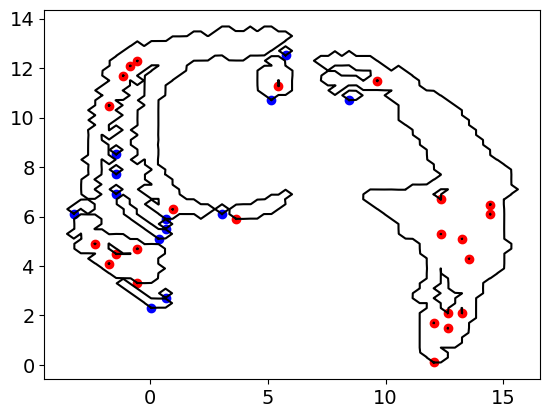

In [56]:
fig = plt.figure()

all_bools = []

for seg in range(37):
    tmp_p = [(all_segs[seg][0,0], all_segs[seg][0,1])]
    
    tmp_bools = []
    for seg2 in range(len(all_segs)):
        path = mpltPath.Path(all_segs[seg2])
        tmp_bool = path.contains_points(tmp_p)
#             tmp_bool, ret = OnePointInsideContour(c1.allsegs[0][seg2], tmp_p, 0.2)
#             tmp_bools.append(tmp_bool)
        tmp_bools.append(tmp_bool)
    if any(tmp_bools):
        all_bools.append(True)
        plt.scatter(all_segs[seg][0,0], all_segs[seg][0,1], c='red')
    else:
        all_bools.append(False)
        plt.scatter(all_segs[seg][0,0], all_segs[seg][0,1], c='blue')
    plt.plot(all_segs[seg][:,0], all_segs[seg][:,1], c='black')

In [43]:
any(tmp_bools)

True

In [44]:
def checkContainContour(all_segs):
# all_segs = c1.allsegs[0]
    all_bools = []

    for seg in range(len(all_segs)):
        tmp_p = [(all_segs[seg][0,0], all_segs[seg][0,1])]

        tmp_bools = []
        for seg2 in range(len(all_segs)):
            path = mpltPath.Path(all_segs[seg2])
            tmp_bool = path.contains_points(tmp_p)
            tmp_bools.append(tmp_bool)
        if any(tmp_bools):
            all_bools.append(True)
        else:
            all_bools.append(False)

    return all_bools

In [45]:
c1bools = checkContainContour(c1.allsegs[0])
# c1bools[2] = False
c1_unique = [x for i, x in enumerate(c1.allsegs[0]) if not c1bools[i]]

In [46]:
c2bools = checkContainContour(c2.allsegs[0])
# c2bools[0] = False
# c2bools[2] = False
# c2bools[31] = False
# c2bools[32] = False
# c2bools[33] = False
c2_unique = [x for i, x in enumerate(c2.allsegs[0]) if not c2bools[i]]


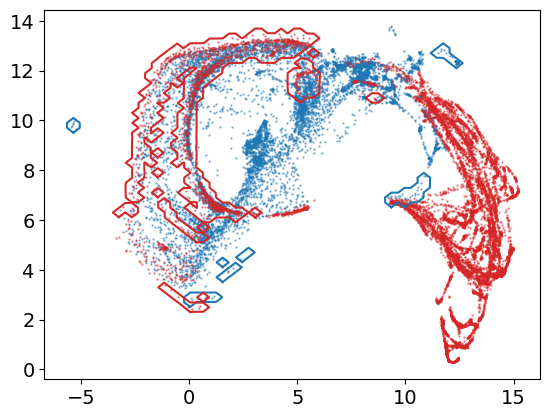

In [47]:
for seg in range(len(c1_unique)):
    plt.plot(c1_unique[seg][:,0], c1_unique[seg][:,1], c='tab:blue')
    
for seg in range(len(c2_unique)):
# for seg in range(3):
    plt.plot(c2_unique[seg][:,0], c2_unique[seg][:,1], c='tab:red')
    
plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='tab:blue', s=0.5, alpha=0.5)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='tab:red', s=0.5, alpha=0.5)



In [48]:
s_points =[(tmp_s.UMAP1.iloc[n], tmp_s.UMAP2.iloc[n]) for n in range(len(tmp_s))]
l_points =[(tmp_l.UMAP1.iloc[n], tmp_l.UMAP2.iloc[n]) for n in range(len(tmp_l))]

In [49]:
short_in_long_bool = [False] *len(s_points)

In [50]:
for n in range(len(c2_unique)):
    path = mpltPath.Path(c2_unique[n])
    tmp_bool = path.contains_points(s_points)
    short_in_long_bool = [a or b for a, b in zip(short_in_long_bool, tmp_bool)]
    

In [51]:
short_in_long = [x for i, x in enumerate(s_points) if short_in_long_bool[i]]
short_not_in = [x for i, x in enumerate(s_points) if not short_in_long_bool[i]]
short_in_long_arr = np.array(short_in_long)
short_not_in = np.array(short_not_in)

In [52]:
long_in_short_bool = [False] *len(l_points)

In [53]:
for n in range(len(c1_unique)):
    path = mpltPath.Path(c1_unique[n])
    tmp_bool = path.contains_points(l_points)
    long_in_short_bool = [a or b for a, b in zip(long_in_short_bool, tmp_bool)]

In [54]:
long_in_short = [x for i, x in enumerate(l_points) if long_in_short_bool[i]]
long_not_in = [x for i, x in enumerate(l_points) if not long_in_short_bool[i]]
long_in_short_arr = np.array(long_in_short)
long_not_in = np.array(long_not_in)

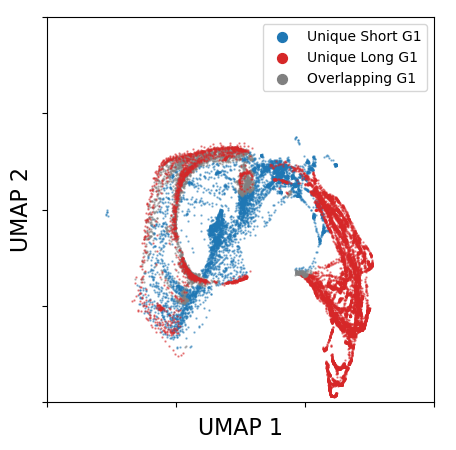

In [55]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

# for seg in range(len(c1_unique)):
#     plt.plot(c1_unique[seg][:,0], c1_unique[seg][:,1], c='tab:blue')
# for seg in range(len(c2_unique)):
#     plt.plot(c2_unique[seg][:,0], c2_unique[seg][:,1], c='tab:red')

plt.scatter(short_not_in[:,0], short_not_in[:,1], c='tab:blue', s=0.5, alpha=0.5, label="Unique Short G1")
plt.scatter(short_in_long_arr[:,0], short_in_long_arr[:,1], c='grey', s=0.5, alpha=0.5)    
    
plt.scatter(long_not_in[:,0], long_not_in[:,1], c='tab:red', s=0.5, alpha=0.5, label="Unique Long G1")
plt.scatter(long_in_short_arr[:,0], long_in_short_arr[:,1], c='grey', s=0.5, alpha=0.5, label="Overlapping G1")


plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

plt.xlabel('UMAP 1', labelpad=-10)
plt.ylabel('UMAP 2', labelpad=-15)

leg = plt.legend(markerscale=10)
for lh in leg.legend_handles: 
    lh.set_alpha(1)
    
    